# Klasifikasi Biner: Raisin Dataset

Dataset Raisin memuat fitur morfologi butiran kismis dari dua kultivar berbeda di Turki, yaitu Kecimen dan Besni. Fitur diekstraksi dari citra digital butiran kismis menggunakan teknik analisis citra.

- Nama dataset: Raisin
- Sumber data: UCI Machine Learning Repository (ID: 850)
- Link dataset: https://archive.ics.uci.edu/dataset/850/raisin
- Dimensi data: 900 baris dan 8 kolom (7 fitur visual dan 1 kolom target)
- Variabel target: Kolom `Class` yang berisi dua varietas kismis: Kecimen dan Besni

In [1]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

raisin = fetch_ucirepo(id=850)
X = raisin.data.features
y = raisin.data.targets
df = pd.concat([X, y], axis=1)

print("Shape data:", df.shape)
display(df.head())
print("\nTipe data:")
print(df.dtypes)

Shape data: (900, 8)


,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen



Tipe data:
Area                 int64
MajorAxisLength    float64
MinorAxisLength    float64
Eccentricity       float64
ConvexArea           int64
Extent             float64
Perimeter          float64
Class                  str
dtype: object


Nilai unik target: ['Besni', 'Kecimen'] => biner: True

Distribusi kelas:
Class
Kecimen    450
Besni      450
Name: count, dtype: int64


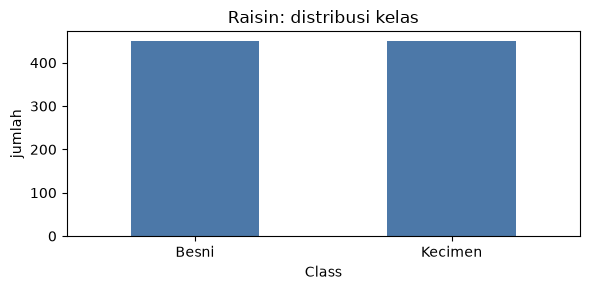

In [2]:
import matplotlib.pyplot as plt

def plot_dist(y, title, rot=0):
    ax = pd.Series(y).value_counts().sort_index().plot(kind="bar", figsize=(6, 3), color="#4C78A8")
    ax.set_title(title)
    ax.set_ylabel("jumlah")
    plt.xticks(rotation=rot)
    plt.tight_layout()
    plt.show()

target_col = "Class"

print("Nilai unik target:", sorted(df[target_col].unique()), "=> biner:", df[target_col].nunique() == 2)
print("\nDistribusi kelas:")
print(df[target_col].value_counts())
plot_dist(df[target_col], "Raisin: distribusi kelas")

In [3]:
assert df[target_col].nunique() == 2, "Nilai unik target harus berjumlah 2"
assert set(df[target_col].unique()) == {"Kecimen", "Besni"}, "Nilai kategori target tidak sesuai"
assert df[target_col].isnull().sum() == 0, "Target mengandung nilai null"
assert df.shape == (900, 8), f"Bentuk dataframe tidak sesuai: {df.shape}"

print("Semua verifikasi lolos.")

Semua verifikasi lolos.


## Kesimpulan

Dataset Raisin tergolong klasifikasi biner karena kolom target `Class` hanya memuat 2 nilai diskret: Kecimen (450 sampel) dan Besni (450 sampel). Setiap sampel kismis dikelompokkan ke dalam salah satu kelas dengan rasio seimbang 50:50.